<a href="https://colab.research.google.com/github/adamcramer400/cvd-women--team-trench-/blob/main/track-02/team/notebooks/01_cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 Cleaning: Track 2, Cardiovascular Health in Women

This notebook loads each dataset, cleans it and records every rule in `team/docs/cleaning_log.md`.

**How to use it**

- Run the cells from top to bottom (**Runtime > Run all** on Colab).
- Cells marked **You decide** have settings set to `None`. The notebook prints a reminder until you fill them in.
- Only clean the datasets you use. Skip the other sections.

Read [`2-the-data.md`](../../2-the-data.md) first if you have not.

In [1]:
# Setup: run this cell first. It finds the track folder and the data.
import re, sys, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PUBLIC_REPO = "https://github.com/Harvard-Undergraduate-OpenBio/openbio-datathon-2026.git"
IN_COLAB = "google.colab" in sys.modules

def find_track_dir():
    here = Path.cwd().resolve()
    for folder in [here, *here.parents]:
        if (folder / "track-02" / "data").is_dir():
            return folder / "track-02"
        if folder.name == "track-02" and (folder / "data").is_dir():
            return folder
    if IN_COLAB:
        dest = Path("/content/openbio-datathon-2026")
        if not dest.exists():
            subprocess.run(["git", "clone", "--depth", "1", PUBLIC_REPO, str(dest)], check=True)
        return dest / "track-02"
    return None

TRACK = find_track_dir()
TEAM = TRACK / "team" if TRACK else Path.cwd()
CLEAN = TEAM / "data_clean"
FIGURES = TEAM / "figures"
for folder in (CLEAN, FIGURES, TEAM / "docs"):
    folder.mkdir(parents=True, exist_ok=True)

SEARCH_DIRS = [d for d in [TRACK / "data" if TRACK else None, TRACK / "data" / "gbd" if TRACK else None,
               Path.cwd(), Path("/content"), Path("/content/drive/MyDrive/datathon")] if d]

def missing(name):
    print(f"Fill in {name} in the cell above, then rerun this cell.")

print("Track folder:", TRACK)
print("Team folder: ", TEAM)
if IN_COLAB:
    print("On Colab, outputs are saved in this session only. Download them or copy them into your team repository.")


Track folder: /content/openbio-datathon-2026/track-02
Team folder:  /content/openbio-datathon-2026/track-02/team
On Colab, outputs are saved in this session only. Download them or copy them into your team repository.


## Helpers

You do not need to edit this cell. `log_step` records a cleaning rule and how many records it affected.

In [2]:
LOG = []

def log_step(dataset, rule, before, after, reason=""):
    """Record one cleaning rule. before and after are row counts."""
    LOG.append({"Dataset": dataset, "Rule": rule, "Reason": reason,
                "Records before": before, "Records after": after,
                "Records affected": before - after})
    print(f"[{dataset}] {rule}: {before - after:,} records affected ({after:,} remain)")

def write_log():
    path = TEAM / "docs" / "cleaning_log.md"
    lines = ["# Cleaning Log", "", "Written by `01_cleaning.ipynb`. Rerun the notebook to update it.", "",
             "| Dataset | Rule | Reason | Records before | Records after | Records affected |",
             "|---|---|---|---|---|---|"]
    for r in LOG:
        lines.append(f"| {r['Dataset']} | {r['Rule']} | {r['Reason']} | {r['Records before']:,} | "
                     f"{r['Records after']:,} | {r['Records affected']:,} |")
    path.write_text("\n".join(lines) + "\n")
    print(f"Wrote {len(LOG)} rules to {path}")

def find_file(*names):
    """Return the first non-empty file matching any name. Empty placeholders are skipped."""
    for folder in SEARCH_DIRS:
        for name in names:
            p = folder / name
            if p.is_file() and p.stat().st_size > 0:
                return p
    return None

def load_csv(path, **kwargs):
    """Read a CSV, detecting whether it uses commas or semicolons."""
    with open(path, encoding="utf-8-sig") as f:
        first = f.readline()
    sep = ";" if first.count(";") > first.count(",") else ","
    return pd.read_csv(path, sep=sep, **kwargs)

def load_table(path, header=None):
    """Read a CSV or Excel table. header=None keeps every row so you can see the real headers."""
    if path.suffix.lower() in (".xlsx", ".xls"):
        return pd.read_excel(path, header=header)
    return load_csv(path, header=header)


---
# Dataset 1: Cardiovascular Disease Dataset

In [3]:
d1_path = find_file("cardiovascular_dataset_OpenBio_Final.csv")
if d1_path:
    d1_raw = load_csv(d1_path)
    print(f"Dataset 1: {d1_raw.shape[0]:,} rows, {d1_raw.shape[1]} columns")
    display(d1_raw.head())
else:
    d1_raw = None
    print("Dataset 1 not found or still an empty placeholder. Skip this section or add the file to track-02/data/.")


Dataset 1: 70,000 rows, 13 columns


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


### Step 1: Duplicates and age

Age is stored in days. This converts it to years.

In [4]:
if d1_raw is not None:
    d1 = d1_raw.copy()
    n = len(d1)
    d1 = d1.drop_duplicates(subset="id")
    log_step("D1", "Drop duplicate ids", n, len(d1), "Each patient should appear once")
    d1["age_years"] = d1["age"] / 365.25
    print(d1["age_years"].describe().round(1))


[D1] Drop duplicate ids: 0 records affected (70,000 remain)
count    70000.0
mean        53.3
std          6.8
min         29.6
25%         48.4
50%         53.9
75%         58.4
max         64.9
Name: age_years, dtype: float64


In [5]:
if d1_raw is not None:
    n = len(d1)
    d1 = d1.drop_duplicates(subset=[c for c in d1.columns if c not in ("id", "age_years")])
    log_step("D1", "Drop rows identical in every column except id", n, len(d1),
             "Two patients matching on age in days and every measurement is far more likely a repeated entry")

[D1] Drop rows identical in every column except id: 24 records affected (69,976 remain)


### Step 2: Check the sex coding

The Kaggle page lists `gender` only as a "categorical code" and does not say which number is which. Women are shorter on average, so the code with the lower mean height is women. In this file that is code 1. If the check below disagrees, change `WOMEN_CODE`.

**You decide:** `D1_SEX_SCOPE`. Use `"women"` to keep only women, or `"both"` to compare women with men.

In [6]:
WOMEN_CODE = 1
D1_SEX_SCOPE = "women"   # "women" or "both"

if d1_raw is not None:
    print("Mean height (cm) by gender code:")
    print(d1.groupby("gender")["height"].mean().round(1))
    d1["female"] = (d1["gender"] == WOMEN_CODE).astype(int)
    if D1_SEX_SCOPE == "women":
        n = len(d1)
        d1 = d1[d1["female"] == 1].copy()
        log_step("D1", "Keep women only", n, len(d1), "Track focus on women")


Mean height (cm) by gender code:
gender
1    161.4
2    169.9
Name: height, dtype: float64
[D1] Keep women only: 24,467 records affected (45,509 remain)


### Step 3: Look at the measurements

Before choosing a rule, look at the values. The table shows the smallest and largest values, and the plots show where most values sit.

,ap_hi,ap_lo,height,weight
count,45509.0,45509.0,45509.0,45509.0
mean,128.1,94.5,161.4,72.6
std,158.1,174.8,7.1,14.2
min,-140.0,-70.0,55.0,21.0
0.1%,12.0,40.0,120.0,39.5
1%,90.0,60.0,145.0,46.0
50%,120.0,80.0,161.0,70.0
99%,180.0,1000.0,178.0,116.0
99.9%,210.0,1100.0,187.0,145.5
max,16020.0,11000.0,250.0,200.0


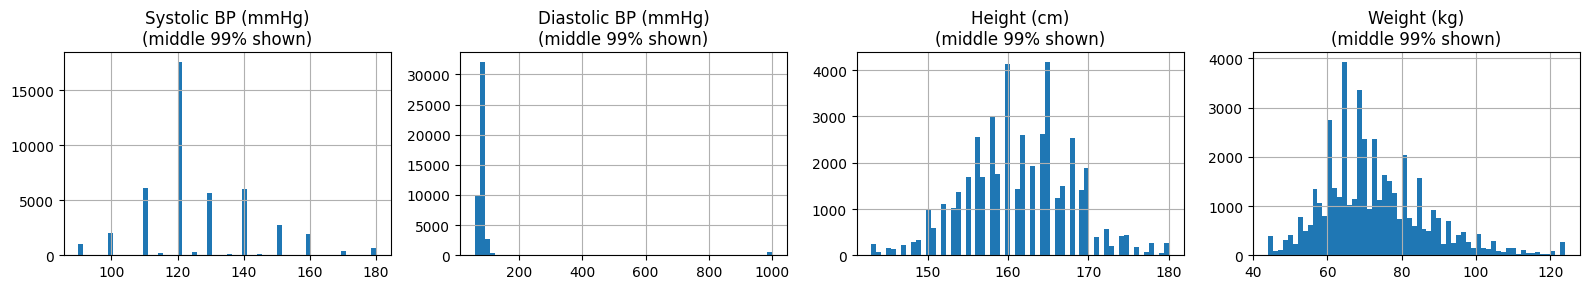

In [7]:
MEASURES = {"ap_hi": "Systolic BP (mmHg)", "ap_lo": "Diastolic BP (mmHg)",
            "height": "Height (cm)", "weight": "Weight (kg)"}

if d1_raw is not None:
    display(d1[list(MEASURES)].describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).round(1))
    fig, axes = plt.subplots(1, 4, figsize=(16, 3))
    for ax, (col, label) in zip(axes, MEASURES.items()):
        lo, hi = d1[col].quantile([0.005, 0.995])
        d1[col].clip(lo, hi).hist(bins=60, ax=ax)
        ax.set_title(label + "\n(middle 99% shown)")
    plt.tight_layout()
    plt.show()


### Step 4: Plausibility rules

**You decide:** a range for each measurement, written as `(low, high)`, and a one-sentence reason. Rows outside the range are removed. Leave a range as `None` to skip it, but note that impossible values will stay in.

In [8]:
RANGES = {
    "ap_hi":  {"range": (70, 250),  "reason": "Systolic pressure outside 70 to 250 mmHg is not compatible with a routine exam and suggests an entry error"},
    "ap_lo":  {"range": (40, 150),  "reason": "Diastolic pressure outside 40 to 150 mmHg is not compatible with a routine exam and suggests an entry error"},
    "height": {"range": (130, 200), "reason": "Adult heights outside 130 to 200 cm are rare enough to be likely entry errors"},
    "weight": {"range": (35, 200),  "reason": "Adult weights under 35 kg are implausible at these heights"},
}

if d1_raw is not None:
    for col, rule in RANGES.items():
        if rule["range"] is None:
            missing(f'RANGES["{col}"]')
            continue
        lo, hi = rule["range"]
        n = len(d1)
        d1 = d1[d1[col].between(lo, hi)]
        log_step("D1", f"Keep {col} between {lo} and {hi}", n, len(d1), rule["reason"])

    n = len(d1)
    d1 = d1[d1["ap_hi"] > d1["ap_lo"]]
    log_step("D1", "Keep rows where systolic > diastolic", n, len(d1), "Systolic is always higher than diastolic")


[D1] Keep ap_hi between 70 and 250: 151 records affected (45,358 remain)
[D1] Keep ap_lo between 40 and 150: 604 records affected (44,754 remain)
[D1] Keep height between 130 and 200: 55 records affected (44,699 remain)
[D1] Keep weight between 35 and 200: 12 records affected (44,687 remain)
[D1] Keep rows where systolic > diastolic: 48 records affected (44,639 remain)


### Step 5: BMI and ordered categories

BMI is calculated after cleaning height and weight. Cholesterol and glucose become ordered labels so plots and models keep their order.

In [9]:
LEVELS = {1: "normal", 2: "above normal", 3: "well above normal"}

if d1_raw is not None:
    d1["bmi"] = d1["weight"] / (d1["height"] / 100) ** 2
    for col in ("cholesterol", "gluc"):
        d1[col + "_level"] = pd.Categorical(d1[col].map(LEVELS), categories=list(LEVELS.values()), ordered=True)
    display(d1[["age_years", "bmi", "ap_hi", "ap_lo"]].describe().round(1))
    print(d1["cholesterol_level"].value_counts().sort_index())
    d1.to_csv(CLEAN / "d1_clean.csv", index=False)
    print(f"Saved {len(d1):,} rows to {CLEAN / 'd1_clean.csv'}")


,age_years,bmi,ap_hi,ap_lo
count,44639.0,44639.0,44639.0,44639.0
mean,53.4,27.9,125.9,80.8
std,6.7,5.6,16.7,9.5
min,29.7,12.3,70.0,40.0
25%,49.4,23.9,120.0,80.0
50%,54.0,26.7,120.0,80.0
75%,58.4,30.9,140.0,90.0
max,64.9,85.8,240.0,150.0


cholesterol_level
normal               32962
above normal          6248
well above normal     5429
Name: count, dtype: int64
Saved 44,639 rows to /content/openbio-datathon-2026/track-02/team/data_clean/d1_clean.csv


This notebook is part of a student data analysis. It is not medical advice, a diagnostic tool or clinical guidance